In [18]:
import os, glob
import numpy as np, pandas as pd, torch, anndata as ad
from pathlib import Path

RUN_NAME = "su007_post"
PT_DIR   = "/DATA1/Roxana/Hierarchy/B Cell Receptor Diversity/su007/post"
VOCAB_PATH = "/DATA1/Roxana/Hierarchy/Two_levels/default_gene_vocab.json"
CHECKPOINT = "/DATA1/Roxana/hebi_repo/notebooks/hebi_hybrid_oldL0.pt"
WORK_DIR   = Path(f"./results_v2/{RUN_NAME}")

LABEL_COLS     = ["timepoint", "tissue"]
N_CELL_CLUSTERS = 10            # k-means روی z0
NICHE_KS        = [6, 8, 10]    # resolutionهای نیچ
NUM_EPOCHS = 15
LR         = 1e-3
SEED       = 2025
DEVICE     = "cuda:0"

H5AD_DIR = WORK_DIR / "h5ad"
OUT_DIR  = WORK_DIR / "results"
H5AD_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

section_files = sorted(os.path.basename(p) for p in glob.glob(os.path.join(PT_DIR, "*.pt")))
sample_ids = [f.replace(".pt", "") for f in section_files]
print(f"{len(section_files)} sections:", sample_ids)

1 sections: ['su007_Post_Tumor_GSM8831638']


In [2]:
def build_sample_adata(pt_dir, files, label_cols, h5ad_dir):
    """One AnnData per sample, written to disk, plus its label row."""
    paths, labels = [], []

    for f in files:
        d = torch.load(os.path.join(pt_dir, f), map_location="cpu",
                       weights_only=False)

        X = d["X"]
        X = X.float().numpy() if torch.is_tensor(X) else np.asarray(X, float)
        coords = d["coords"]
        coords = coords.numpy() if torch.is_tensor(coords) else np.asarray(coords)

        a = ad.AnnData(X=X)
        a.var_names = [str(g) for g in d["gene_names"]]
        a.var_names_make_unique()
        a.obsm["spatial"] = np.asarray(coords, dtype=float)

        sid = str(d.get("sample_id", f.replace(".pt", "")))
        row = {"sample_id": sid,
               "patient_id": str(d.get("patient_id", "unknown"))}
        d_labels = d.get("labels", {})
        for c in label_cols:
            val = d_labels.get(c, d.get(c, np.nan))
            row[c] = "nan" if pd.isna(val) else str(val)

        out = Path(h5ad_dir) / f"{sid}.h5ad"
        a.write_h5ad(out)
        paths.append(str(out))
        labels.append(row)

    return paths, pd.DataFrame(labels)


h5ad_files, label_df = build_sample_adata(
    PT_DIR, section_files, LABEL_COLS, H5AD_DIR
)
print(label_df.to_string(index=False))

                  sample_id patient_id timepoint tissue
su007_Post_Tumor_GSM8831638      su007      Post  Tumor


In [3]:
a0 = ad.read_h5ad(h5ad_files[0])
block = a0.X[:500]
block = block.toarray() if hasattr(block, "toarray") else np.asarray(block)
integral = np.allclose(block, np.round(block))
print(f"{a0.n_obs:,} cells, {a0.n_vars} genes in the first sample")
print("X looks like:", "raw counts" if integral else "already transformed",
      f"(max {block.max():.2f})")
del a0, block

print()
for c in LABEL_COLS:
    print(f"{c}: " + "  ".join(
        f"{k}={v}" for k, v in label_df[c].value_counts().items()))
print("patients:", label_df.patient_id.nunique())

13,313 cells, 478 genes in the first sample
X looks like: already transformed (max 8.37)

timepoint: Post=1
tissue: Tumor=1
patients: 1


In [4]:
from hebi.inference.pipeline import encode_sections, cluster_sections

PREPROCESS = False        # set False if the check above said "already transformed"

sections, ctx = encode_sections(
    checkpoint_path=CHECKPOINT,
    data_dir=PT_DIR,
    section_files=section_files,
    h5ad_files=h5ad_files,
    vocab_path=VOCAB_PATH,
    section_labels=sample_ids,

    mode="continual",
    init="pretrained",
    num_epochs=NUM_EPOCHS,
    lr=LR,

    grn=False,
    species="Human",

    preprocess=PREPROCESS,
    output_dir=str(OUT_DIR),
    device=DEVICE,
    seed=SEED,
)
print(f"\n{len(sections)} samples encoded")

/home/tower4/miniconda3/envs/hebi/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Seed set to 2025
Loading results_v2/su007_post/h5ad/su007_Post_Tumor_GSM8831638.h5ad
Covered genes: 478/478 (100.00%)
  13313 cells, 478 genes
  su007_Post_Tumor_GSM8831638.pt: 13313 cells, already aligned

Loading checkpoint: /DATA1/Roxana/hebi_repo/notebooks/hebi_hybrid_oldL0.pt
Re-initialising niche-level modules
Orthogonal init for niche prototypes
Fresh optimiser state for continual adaptation

Continual adaptation: 15 epochs over 1 sections
  epoch   1  loss  7.8645  (1s)
  epoch   2  loss  6.0079  (1s)
  epoch   3  loss  5.5575  (1s)
  epoch   4  loss  5.2544  (1s)
  epoch   5  loss  5.1095  (1s)
  epoch   6  loss  5.0282  (1s)
  epoch   7  loss  4.9669  (1s)
  epoch   8  loss  4.9013  (1s)
  epoch   9  loss  4.8512  (1s)
  epoch  10  loss  4.8024  (1s)
  epoch  11  loss  4.7297  (1s)
  epoch  12  loss  4.5988  (1s)
  epoch  13  loss  4.4739  (1s)
  epoch  14  loss  4.4102  (1s)
  epoch  15  loss  4.3784  (1s)

Continual adaptation finished. Final loss: 4.3784
🎲 Seed set to 0
--

Encoding /DATA1/Roxana/Hierarchy/B Cell Receptor Diversity/su007/post/su007_Post

  13,313 cells encoded; 18/20 prototypes in use

1 samples encoded



Cell-level clustering: kmeans, k=10  ->  obs['z0_kmeans_10']
Niche-level clustering: 8 niches from 200-neighbour composition  ->  obs['comp_niches_8']

su007_Post_Tumor_GSM8831638
  z0_kmeans_10           FIDE=0.7740
  prototypes             FIDE=0.8339
  comp_niches_8          FIDE=0.9622

  Saved z0_kmeans_10 (s=4.0)
  Saved comp_niches_8 (s=4.0)


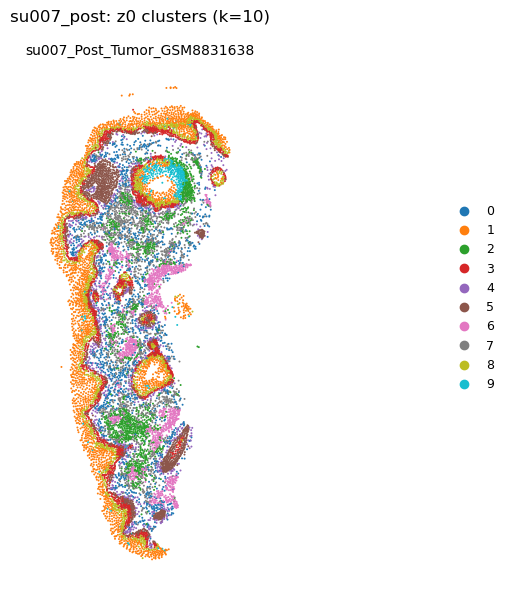

In [19]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D

def plot_labels(sections, key, names, title, out=None, s=2):
    cats = sorted(set().union(*[set(a.obs[key].astype(str)) for a in sections]), key=lambda x: (len(x), x))
    cmap = plt.get_cmap("tab20" if len(cats) > 10 else "tab10")
    col = {c: mcolors.to_hex(cmap(i % cmap.N)) for i, c in enumerate(cats)}
    fig, axes = plt.subplots(1, len(sections), figsize=(6 * len(sections), 6), squeeze=False)
    for ax, a, n in zip(axes[0], sections, names):
        xy = np.asarray(a.obsm["spatial"]); lab = a.obs[key].astype(str).values
        ax.scatter(xy[:, 0], xy[:, 1], c=[col[l] for l in lab], s=s, linewidths=0, rasterized=True)
        ax.set_title(n, fontsize=10); ax.set_aspect("equal"); ax.invert_yaxis(); ax.axis("off")
    fig.legend(handles=[Line2D([], [], marker="o", ls="", color=col[c], label=c) for c in cats],
               loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False, fontsize=9)
    fig.suptitle(title); fig.tight_layout()
    if out:
        fig.savefig(f"{out}.png", dpi=300, bbox_inches="tight"); fig.savefig(f"{out}.svg")
    plt.show()

written = cluster_sections(sections, ctx, n_cell_clusters=N_CELL_CLUSTERS,
                           n_composition_niches=8, composition_neighbors=200,
                           cluster_method="kmeans", point_size=4)
cell_key = written["cell_clusters"]
plot_labels(sections, cell_key, sample_ids, f"{RUN_NAME}: z0 clusters (k={N_CELL_CLUSTERS})",
            out=OUT_DIR / f"{RUN_NAME}_{cell_key}")

18/20 prototypes in use; tiny (<0.5%): ['13']
           n_su007_Post_Tumor_GSM8831638  q_su007_Post_Tumor_GSM8831638  pi_su007_Post_Tumor_GSM8831638                      support   tiny
prototype                                                                                                                                  
0                                    912                       0.068504                             1.0  su007_Post_Tumor_GSM8831638  False
1                                    294                       0.022084                             1.0  su007_Post_Tumor_GSM8831638  False
2                                    143                       0.010741                             1.0  su007_Post_Tumor_GSM8831638  False
4                                    783                       0.058815                             1.0  su007_Post_Tumor_GSM8831638  False
5                                    785                       0.058965                             1.0  su007_Pos

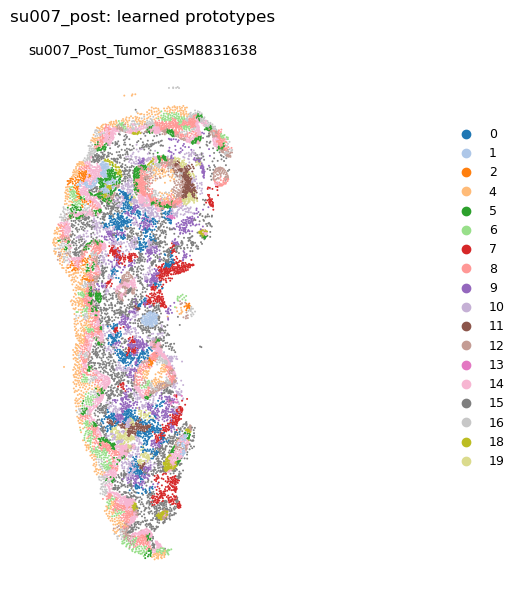

In [6]:
from hebi.inference.niches import prototype_table

labels = [a.obs["prototypes"].astype(str).values for a in sections]
ptab, occupied, support, pi, tiny = prototype_table(labels, sample_ids)
print(f"{len(occupied)}/20 prototypes in use; tiny (<0.5%): {sorted(tiny, key=int)}")
print(ptab.to_string())

plot_labels(sections, "prototypes", sample_ids, f"{RUN_NAME}: learned prototypes",
            out=OUT_DIR / f"{RUN_NAME}_prototypes")

Encoding /DATA1/Roxana/Hierarchy/B Cell Receptor Diversity/su007/post/su007_Post


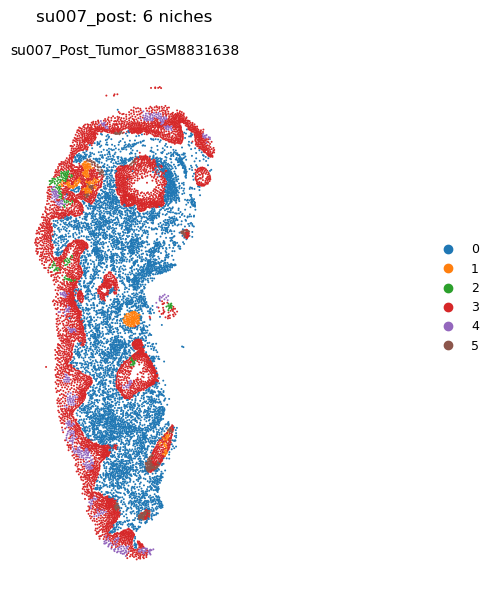

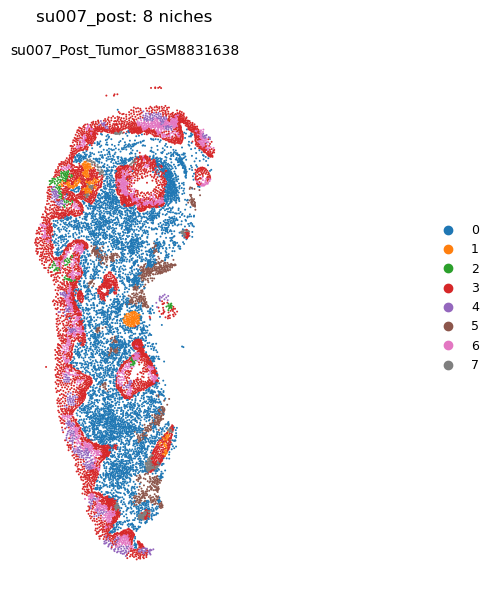

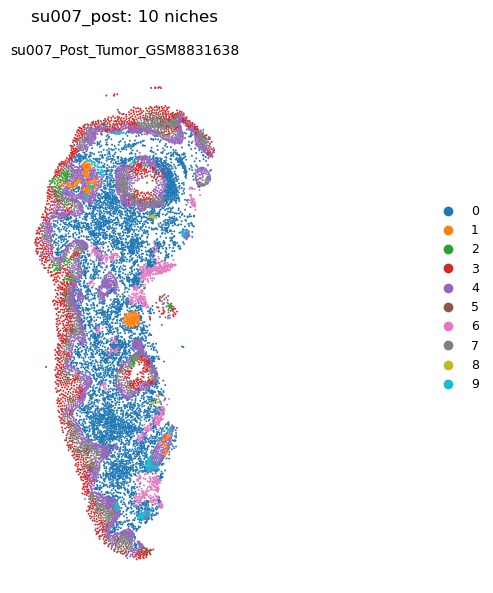

In [7]:
import io, contextlib, warnings
from hebi.inference.niches import assign_niches
#NICHE_KS = [16, 18, 20]
with contextlib.redirect_stdout(io.StringIO()), warnings.catch_warnings():
    warnings.simplefilter("ignore")
    assign_niches(sections, ctx, PT_DIR, section_files, n_niches=NICHE_KS,
                  section_names=sample_ids, cache_dir=OUT_DIR)

for k in NICHE_KS:
    plot_labels(sections, f"niche_k{k}", sample_ids, f"{RUN_NAME}: {k} niches",
                out=OUT_DIR / f"{RUN_NAME}_niche_k{k}")

In [10]:
genes = ['PTCH2', 'PTCH1', 'GLI1', 'GJB6', 'CXCL14', 'STMN1', 'KRT5', 'KRT15', 'TP63',
         'KRT16', 'S100A8', 'DCT', 'TYRP1', 'JCHAIN', 'MZB1', 'IGKC', 'PTPRC', 'CD3E', 'LYZ']
genes = [g for g in genes if g in adata.var_names]
X = adata[:, genes].X
X = X.toarray() if hasattr(X, 'toarray') else np.asarray(X)
expr = pd.DataFrame(X > 0, columns=genes, index=adata.obs_names)
cl = adata.obs[cell_key].astype(str).values
print((expr.groupby(cl).mean() * 100).round(0).astype(int).assign(n=pd.Series(cl).value_counts()).to_string())

   PTCH2  GJB6  CXCL14  STMN1  KRT5  KRT15  TP63  KRT16  S100A8  DCT  TYRP1  JCHAIN  MZB1  IGKC  PTPRC  CD3E  LYZ     n
0      6     2      67     12    25     17     3      3      12    2      3       5     2    36     12     7   35  1295
1      3    44      24     16    56     34    60     37      99    3      5       1     1    16      6     2    6  2257
2      2     0      41      9    15      8     3      4      15    1      2      12     3    42     72    40   82  1342
3      5    13      82     39    99     97    87     48      77   36     41       1     1    13      8     2   12  1612
4      5     5      62     16    64     53    18      7      24   10     16       4     2    23     17     7   42   743
5     35    47      91     47    98     97    80     28      32   45     50       2     1    22      6     2   10  1592
6      3     1      38      7     5      4     1      1       5    3      0      42    39    87     33    17   35  1086
7      3     1      64      8    14     

In [11]:
nk = adata.obs['niche_k8'].astype(str).values
print((expr.groupby(nk).mean() * 100).round(0).astype(int)[['PTCH2', 'GJB6', 'DCT', 'TYRP1', 'KRT16']]
      .assign(n=pd.Series(nk).value_counts()).to_string())

   PTCH2  GJB6  DCT  TYRP1  KRT16     n
0      3     1    3      4      4  5467
1     72    76   28     40     19   296
2      6    38    1      3     87   143
3      8    30   25     29     42  4644
4      2    39    6      7     29   441
5      5     1    4      1      1   760
6      3    17   10     13     42  1274
7     38    47   47     41     22   288


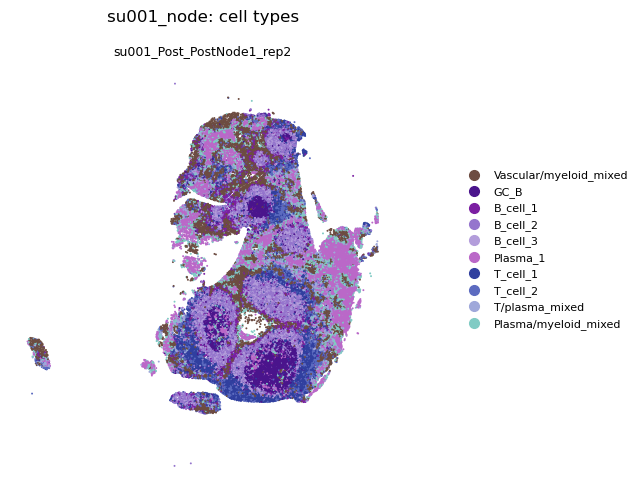

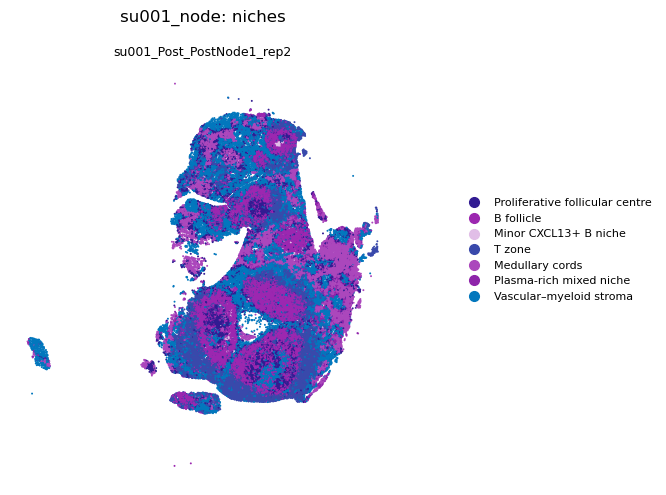

In [13]:
node_dir = Path('./results_v2/su001_node')
ann = pd.read_csv(node_dir / 'results/su001_node_cell_niche_annotation.csv', index_col='cell_id')

parts = []
for f in sorted((node_dir / 'h5ad').glob('*.h5ad')):
    a = ad.read_h5ad(f)
    a.obs['sample_id'] = f.stem
    a.obs_names = f.stem + '|' + a.obs_names.astype(str)
    parts.append(a)
node = ad.concat(parts)

node = node[ann.index].copy()            # همون ترتیب CSV
node.obs[['cell_type', 'niche_type']] = ann[['cell_type', 'niche_type']].values

plot_annotation(node, 'cell_type',  CELL_PALETTE,  'su001_node: cell types', node_dir / 'results/su001_node_celltype.png')
plot_annotation(node, 'niche_type', NICHE_PALETTE, 'su001_node: niches',     node_dir / 'results/su001_node_niche.png')

In [9]:
import anndata as ad, numpy as np, pandas as pd, scanpy as sc

def top_de(adata, key, n=10):
    df = sc.get.rank_genes_groups_df(adata, group=None, key=key)
    df = df[(df['pvals_adj'] < 0.05) & (df['logfoldchanges'] > 0)]
    return (df.sort_values(['group', 'scores'], ascending=[True, False])
              .groupby('group', observed=True).head(n)[['group', 'names', 'logfoldchanges', 'pvals_adj']])

def annotate_run_v2(sections, names, run_name, out_dir, cell_key, niche_keys, n_genes=10):
    """One HEBI run: DE on z0 clusters once, and on every niche resolution. One Excel per run."""
    adata = ad.concat(sections, label='sample_id', keys=names, index_unique='|')

    blk = adata.X[:500]
    blk = blk.toarray() if hasattr(blk, 'toarray') else np.asarray(blk)
    if np.allclose(blk, np.round(blk)):
        sc.pp.normalize_total(adata); sc.pp.log1p(adata)

    for k in [cell_key, *niche_keys]:
        adata.obs[k] = adata.obs[k].astype(str).astype('category')

    sc.tl.rank_genes_groups(adata, groupby=cell_key, method='wilcoxon', key_added='cell_de')
    for nk in niche_keys:
        sc.tl.rank_genes_groups(adata, groupby=nk, method='wilcoxon', key_added=f'{nk}_de')

    with pd.ExcelWriter(out_dir / f'{run_name}_annotation_input.xlsx') as w:
        top_de(adata, 'cell_de', n_genes).to_excel(w, sheet_name='cell_clusters_top', index=False)
        for nk in niche_keys:
            top_de(adata, f'{nk}_de', n_genes).to_excel(w, sheet_name=f'{nk}_top', index=False)
            pd.crosstab(adata.obs[nk], adata.obs[cell_key], normalize='index').round(2) \
              .to_excel(w, sheet_name=f'{nk}_composition')
            pd.crosstab(adata.obs[nk], adata.obs[cell_key], normalize='columns').round(2) \
              .to_excel(w, sheet_name=f'{nk}_celltype_dist')

    adata.obs[[cell_key, *niche_keys]].rename_axis('cell_id') \
         .to_csv(out_dir / f'{run_name}_cluster_labels.csv')
    return adata

adata = annotate_run_v2(sections, sample_ids, RUN_NAME, OUT_DIR,
                        cell_key=cell_key, niche_keys=[f'niche_k{k}' for k in NICHE_KS])

In [9]:
genes = ['PTCH2', 'PTCH1', 'GLI1', 'GJB6', 'CXCL14', 'STMN1', 'KRT5', 'KRT15', 'TP63',
         'KRT16', 'S100A8', 'DCT', 'TYRP1', 'PMEL', 'JCHAIN', 'MZB1', 'IGKC', 'PTPRC', 'CD3E', 'LYZ']
genes = [g for g in genes if g in adata.var_names]
X = adata[:, genes].X
X = X.toarray() if hasattr(X, 'toarray') else np.asarray(X)
expr = pd.DataFrame(X > 0, columns=genes, index=adata.obs_names)
cl = adata.obs[cell_key].astype(str).values
pct = (expr.groupby(cl).mean() * 100).round(0).astype(int)
print(pct.assign(n=pd.Series(cl).value_counts()).to_string())

   PTCH2  GJB6  CXCL14  STMN1  KRT5  KRT15  TP63  KRT16  S100A8  DCT  TYRP1  PMEL  JCHAIN  MZB1  IGKC  PTPRC  CD3E  LYZ     n
0      5    22      74     52   100     88    81     54      78   20     30     9       0     0    20     10     3   11   428
1      4     1      38     11    10      6     2      2      13    2      2     1      24     9    59     29    14   21  2675
2      3    59      12      9    51     26    50     44      99    1      3     3       2     3    35     11     6    5  1020
3      5    16      44     45    95     61    68     36      24    2      9     1       1     2    19      4     2    6   276
4      2    12      82     41    99     88    85     53      87   18     28     8       1     1    17      8     4   13  1165
5      9     1      64     16    31     23     7      4      19    4      5     1       5     2    23     22    11   25   684
6      3    22      40     26    83     57    76     51      94    3      7     3       1     1    19      5     2    

In [11]:
names = [Path(f).stem for f in h5ad_files]
assert len(names) == len(sections)
adata = ad.concat(sections, label='sample_id', keys=names, index_unique=None)
adata.obs_names = (adata.obs['sample_id'].astype(str) + '|'
                   + np.concatenate([s.obs_names.astype(str) for s in sections])).values
adata = annotate_run(adata, RUN_NAME, OUT_DIR, cell_key=cell_key, niche_key=niche_key)
print(adata.obs['sample_id'].value_counts().to_string())

su007_pre: 48,149 cells → saved Excel + labels to results/skin_SU007/pre/results
sample_id
su007_Pre_Tumor_GSM8831647    48149


/tmp/ipykernel_3736906/3959051101.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('group').head(n)[['group', 'names', 'logfoldchanges', 'pvals_adj']])
/tmp/ipykernel_3736906/3959051101.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('group').head(n)[['group', 'names', 'logfoldchanges', 'pvals_adj']])


In [14]:
def make_annotation(adata, cell_key, niche_key, cell_map, niche_map, name):
    o = adata.obs
    out = pd.DataFrame({
        'cell_type':  o[cell_key].astype(str).map(cell_map).values,
        'niche_type': o[niche_key].astype(str).map(niche_map).values,
    }, index=(o['sample_id'].astype(str) + '|' + o.index.astype(str)).values)
    out.index.name = 'cell_id'
    assert out.isna().sum().sum() == 0, f'{name}: unmapped clusters'
    out.to_csv(OUT_DIR / f'{name}_cell_niche_annotation.csv')
    adata.obs['cell_type'] = out['cell_type'].values
    adata.obs['niche_type'] = out['niche_type'].values
    return out

In [15]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
def plot_annotation(adata, col, palette, title, out_png=None, spatial_key='spatial', s=2):
    xy = adata.obsm[spatial_key]
    labels = adata.obs[col].astype(str)
    missing = sorted(set(labels) - set(palette))
    if missing:
        print('no colour for:', missing, '→ grey')
    samples = adata.obs['sample_id'].astype(str).unique()
    fig, axes = plt.subplots(1, len(samples), figsize=(5 * len(samples), 5), squeeze=False)
    for ax, smp in zip(axes[0], samples):
        m = (adata.obs['sample_id'].astype(str) == smp).values
        ax.scatter(xy[m, 0], xy[m, 1], c=[palette.get(l, '#BDBDBD') for l in labels[m]],
                   s=s, linewidths=0, rasterized=True)
        ax.set_title(smp, fontsize=9); ax.set_aspect('equal'); ax.invert_yaxis(); ax.axis('off')
    present = [l for l in palette if l in set(labels)]
    handles = [Line2D([0], [0], marker='o', ls='', color=palette[l], markersize=7, label=l) for l in present]
    fig.legend(handles=handles, loc='center left', bbox_to_anchor=(1.0, 0.5), frameon=False, fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    if out_png:
        fig.savefig(out_png, dpi=300, bbox_inches='tight')
    plt.show()


In [16]:
CELL_PALETTE = {
    # malignant
    'BCC_1':'#B71C1C', 'BCC_2':'#E53935', 'BCC_3':'#EF9A9A', 'BCC_4':'#880E4F', 'BCC_5':'#FF8A80',
    'BCC_cycling_1':'#E65100', 'BCC_cycling_2':'#FB8C00',
    'BCC_stress_1':'#FFB74D', 'BCC_stress_2':'#FFCC80', 'BCC_squamoid':'#D84315',
    # epithelium
    'Epithelial_KRT6/16+':'#EC407A', 'Epithelial_KRT6/16+_1':'#D81B60', 'Epithelial_KRT6/16+_2':'#F48FB1',
    'Epithelial_SDC1+':'#FFAB91', 'Basal_keratinocyte':'#F8BBD0', 'Basaloid_1':'#C2185B', 'Basaloid_2':'#F06292',
    'Basal/melanocyte_mixed':'#A1887F', 'Melanocyte':'#4E342E',
    # stroma / vascular
    'Fibroblast_1':'#1B5E20', 'Fibroblast_2':'#43A047', 'Fibroblast_3':'#A5D6A7', 'Fibroblast_inflammatory':'#827717',
    'Smooth_muscle/pericyte':'#8D6E63', 'Stromal_vascular':'#BCAAA4', 'Vascular/myeloid_mixed':'#6D4C41',
    'APC/stromal_mixed':'#9E9D24', 'Endothelial':'#1565C0', 'Endothelial_activated':'#42A5F5',
    # lymphoid
    'GC_B':'#4A148C', 'B_cell':'#6A1B9A', 'B_cell_1':'#7B1FA2', 'B_cell_2':'#9575CD', 'B_cell_3':'#B39DDB',
    'Plasma':'#AB47BC', 'Plasma_1':'#BA68C8', 'Plasma_2':'#CE93D8',
    'T_cell':'#283593', 'T_cell_1':'#303F9F', 'T_cell_2':'#5C6BC0', 'Tfh':'#7986CB',
    # myeloid / mixed immune
    'Macrophage_1':'#00897B', 'Macrophage_2':'#4DB6AC', 'Macrophage/DC':'#00796B', 'Immune_mixed':'#26A69A',
    'T/plasma_mixed':'#9FA8DA', 'Plasma/myeloid_mixed':'#80CBC4', 'Plasma/immune_mixed':'#E1BEE7',
    'Unassigned':'#BDBDBD','B/T_mixed':'#8C9EFF',
}

NICHE_PALETTE = {
    # tumour
    'Tumour nest core':'#B71C1C', 'Tumour nest edge':'#EF5350', 'Tumour nest (stress)':'#FFB74D',
    'Invasive front':'#FF9800',
    # epithelium
    'Epidermis':'#D81B60', 'Minor epidermal niche':'#FCE4EC',
    'Hyperproliferative epidermis':'#EC407A', 'Hyperproliferative epidermis 2':'#F06292',
    'Inflamed epidermis':'#AD1457', 'Basal epidermis':'#F48FB1', 'Epidermis (mixed)':'#F8BBD0',
    'Epidermis–tumour interface':'#FFAB91', 'Epithelium–stroma interface':'#FFCCBC', 'Papillary dermis':'#D7CCC8',
    # lymphoid
    'Germinal centre':'#4A148C', 'Proliferative follicular centre':'#311B92', 'B follicle':'#9C27B0',
    'Follicle mantle':'#CE93D8', 'B-cell aggregate':'#7B1FA2', 'Minor CXCL13+ B niche':'#E1BEE7',
    'T zone':'#3949AB', 'Interfollicular zone':'#7986CB', 'T-cell infiltrate':'#283593',
    'Perivascular immune infiltrate':'#7E57C2', 'Immune infiltrate':'#5E35B1',
    'Medullary cords':'#AB47BC', 'Medulla (mixed)':'#EA80FC', 'Plasma-rich stroma':'#BA68C8',
    'Plasma-rich mixed niche':'#8E24AA', 'Plasma-rich vascular stroma':'#D500F9', 'Minor plasma-rich stroma':'#D1C4E9',
    # stroma
    'Perivascular stroma':'#1E88E5', 'Vascular–myeloid stroma':'#0277BD', 'HLA-II+ immune–vascular stroma':'#0D47A1',
    'Inflamed stroma':'#26A69A', 'Peritumoral stroma':'#9CCC65', 'Fibrous stroma':'#558B2F',
    'Dermal stroma':'#33691E', 'Fibrovascular dermis':'#689F38', 'Fibroblast–myeloid dermis':'#00695C',
    'Myeloid-rich stroma':'#004D40',
    'Unassigned':'#BDBDBD','Tumour nest':'#C62828',

'Activated epithelium':'#E91E63',

'HLA-II+ fibrovascular stroma':'#4FC3F7', 'MMP+ fibroblast stroma':'#827717',
'Peritumoral vascular stroma':'#1976D2',
}

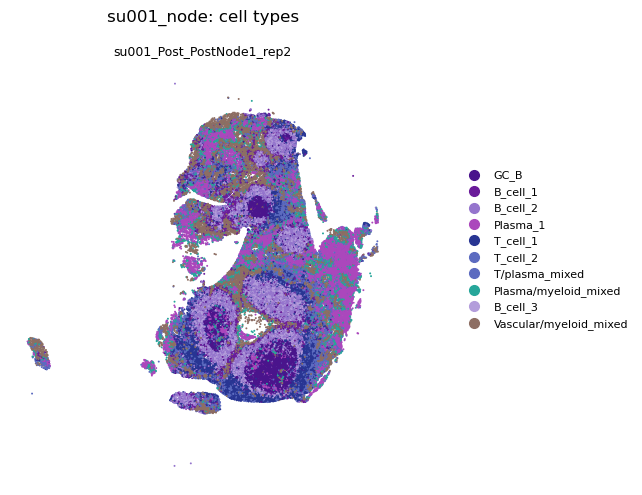

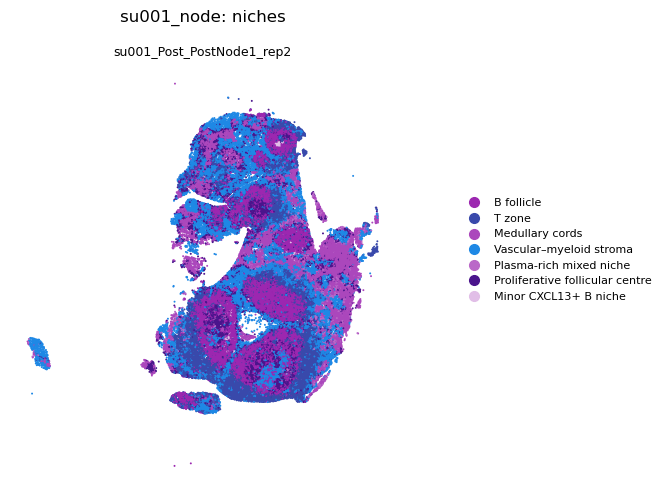

In [27]:
#Node
CHOSEN_K = 8

CELL_PALETTE.update({'T/plasma_mixed':'#5C6BC0', 'Plasma/myeloid_mixed':'#26A69A',
                     'B_cell_3':'#B39DDB', 'Vascular/myeloid_mixed':'#8D6E63'})
NICHE_PALETTE.update({'Vascular–myeloid stroma':'#1E88E5', 'Plasma-rich mixed niche':'#BA68C8',
                      'Proliferative follicular centre':'#4A148C', 'Minor CXCL13+ B niche':'#E1BEE7'})

cell_map = {'0':'B_cell_1', '1':'Plasma_1', '2':'T/plasma_mixed', '3':'T_cell_1',
            '4':'B_cell_2', '5':'T_cell_2', '6':'Vascular/myeloid_mixed', '7':'GC_B',
            '8':'Plasma/myeloid_mixed', '9':'B_cell_3'}
niche_maps = {8: {'0':'Vascular–myeloid stroma', '1':'T zone', '2':'Plasma-rich mixed niche',
                  '3':'B follicle', '4':'Proliferative follicular centre', '5':'Medullary cords',
                  '6':'Minor CXCL13+ B niche', '7':'Minor CXCL13+ B niche'}}
niche_key = f'niche_k{CHOSEN_K}'
adata.obs['cell_type']  = adata.obs[cell_key].astype(str).map(cell_map)
adata.obs['niche_type'] = adata.obs[niche_key].astype(str).map(niche_maps[CHOSEN_K])
assert adata.obs[['cell_type', 'niche_type']].isna().sum().sum() == 0, 'unmapped clusters'

adata.obs[['cell_type', 'niche_type']].rename_axis('cell_id') \
     .to_csv(OUT_DIR / f'{RUN_NAME}_cell_niche_annotation.csv')
plot_annotation(adata, 'cell_type',  CELL_PALETTE,  f'{RUN_NAME}: cell types', OUT_DIR / f'{RUN_NAME}_celltype.png')
plot_annotation(adata, 'niche_type', NICHE_PALETTE, f'{RUN_NAME}: niches',     OUT_DIR / f'{RUN_NAME}_niche.png')

In [25]:
#save_Node
ANNOT_XLSX = Path('./results_v2/su001_annotation.xlsx')
SHEET = RUN_NAME.replace('su001_', '')          # node / skin / pre / post

out = pd.DataFrame({
    'sample_id':    adata.obs['sample_id'].astype(str).values,
    'cell_cluster': adata.obs[cell_key].astype(str).values,
    'niche':        adata.obs[niche_key].astype(str).values,
    'cell_type':    adata.obs['cell_type'].values,
    'niche_type':   adata.obs['niche_type'].values,
}, index=adata.obs_names.rename('cell_id'))

mode = 'a' if ANNOT_XLSX.exists() else 'w'
kw = {'if_sheet_exists': 'replace'} if mode == 'a' else {}
with pd.ExcelWriter(ANNOT_XLSX, mode=mode, engine='openpyxl', **kw) as w:
    out.to_excel(w, sheet_name=SHEET)

In [28]:
#save_Node

orig_idx = adata.obs_names.str.rsplit('|', n=1).str[0]
cell_id  = adata.obs['sample_id'].astype(str).values + '|' + orig_idx

out = pd.DataFrame({'cell_type':  adata.obs['cell_type'].values,
                    'niche_type': adata.obs['niche_type'].values},
                   index=pd.Index(cell_id, name='cell_id'))
out.to_csv(OUT_DIR / f'{RUN_NAME}_cell_niche_annotation.csv')

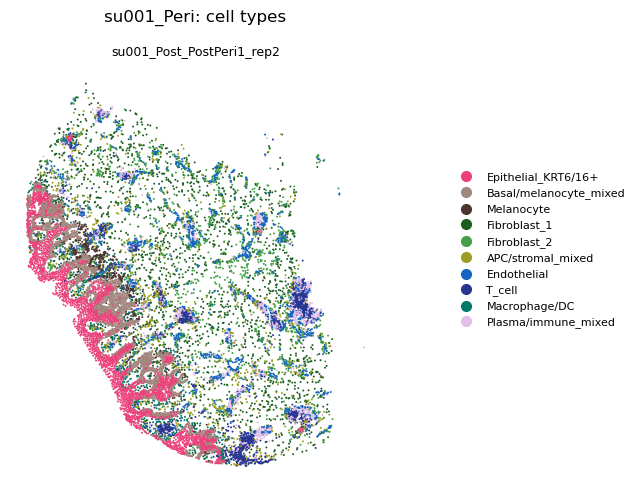

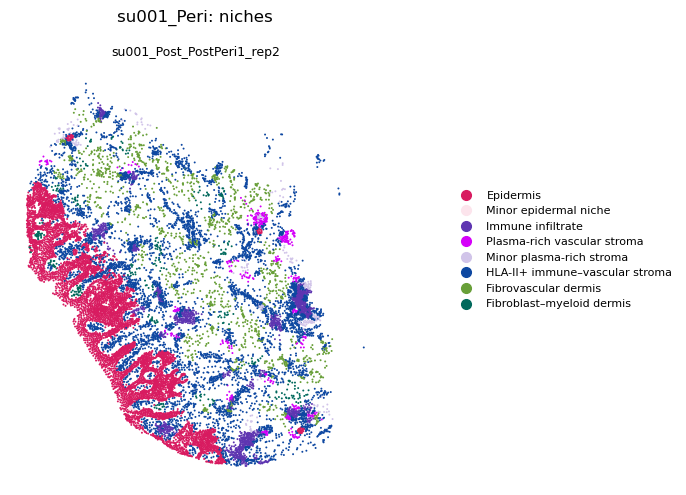

In [14]:
#Peri
CHOSEN_K = 8

cell_map = {'0':'Endothelial', '1':'Basal/melanocyte_mixed', '2':'Plasma/immune_mixed', '3':'Fibroblast_1',
            '4':'Fibroblast_2', '5':'T_cell', '6':'APC/stromal_mixed', '7':'Macrophage/DC',
            '8':'Epithelial_KRT6/16+', '9':'Melanocyte'}
niche_maps = {8: {'0':'Minor epidermal niche', '1':'Immune infiltrate', '2':'Epidermis',
                  '3':'Fibroblast–myeloid dermis', '4':'Fibrovascular dermis',
                  '5':'HLA-II+ immune–vascular stroma', '6':'Plasma-rich vascular stroma',
                  '7':'Minor plasma-rich stroma'}}
niche_key = f'niche_k{CHOSEN_K}'
adata.obs['cell_type']  = adata.obs[cell_key].astype(str).map(cell_map)
adata.obs['niche_type'] = adata.obs[niche_key].astype(str).map(niche_maps[CHOSEN_K])
assert adata.obs[['cell_type', 'niche_type']].isna().sum().sum() == 0, 'unmapped clusters'

orig_idx = adata.obs_names.str.rsplit('|', n=1).str[0]
cell_id  = adata.obs['sample_id'].astype(str).values + '|' + orig_idx
out = pd.DataFrame({'cell_type':  adata.obs['cell_type'].values,
                    'niche_type': adata.obs['niche_type'].values},
                   index=pd.Index(cell_id, name='cell_id'))
out.to_csv(OUT_DIR / f'{RUN_NAME}_cell_niche_annotation.csv')

plot_annotation(adata, 'cell_type',  CELL_PALETTE,  f'{RUN_NAME}: cell types', OUT_DIR / f'{RUN_NAME}_celltype.png')
plot_annotation(adata, 'niche_type', NICHE_PALETTE, f'{RUN_NAME}: niches',     OUT_DIR / f'{RUN_NAME}_niche.png')

In [15]:
#save_Peri
ANNOT_XLSX = Path('./results_v2/su001_annotation.xlsx')
SHEET = RUN_NAME.replace('su001_', '')          # Peri

mode = 'a' if ANNOT_XLSX.exists() else 'w'
kw = {'if_sheet_exists': 'replace'} if mode == 'a' else {}
with pd.ExcelWriter(ANNOT_XLSX, mode=mode, engine='openpyxl', **kw) as w:
    out.to_excel(w, sheet_name=SHEET)

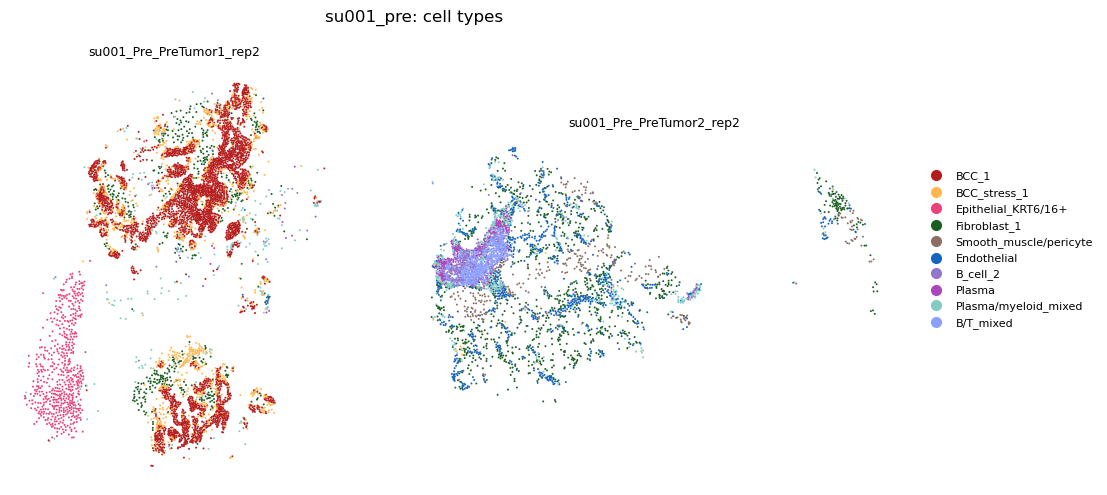

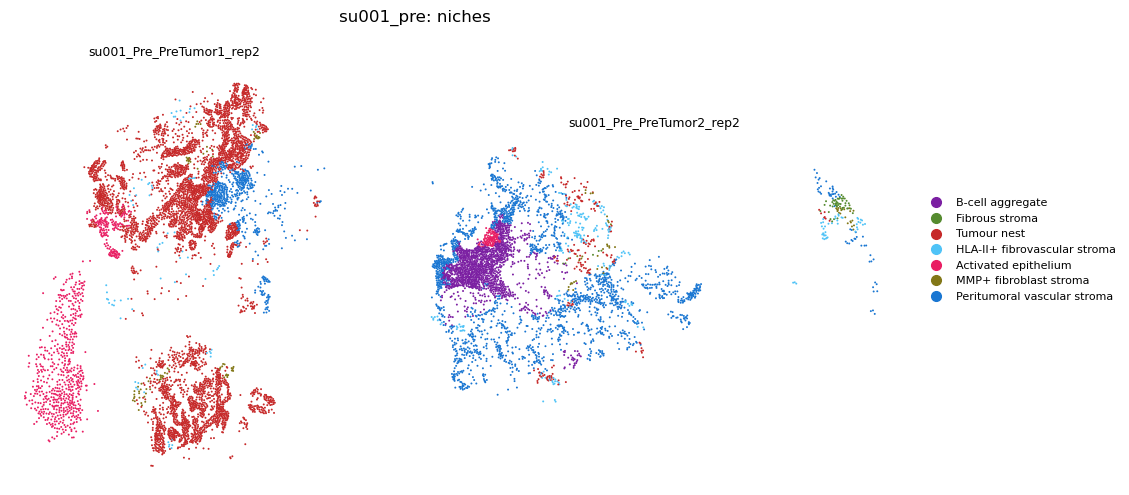

In [12]:
#Pre
CHOSEN_K = 8

cell_map = {'0':'Fibroblast_1', '1':'BCC_1', '2':'Plasma', '3':'Epithelial_KRT6/16+', '4':'Plasma/myeloid_mixed',
            '5':'BCC_stress_1', '6':'B/T_mixed', '7':'Smooth_muscle/pericyte', '8':'Endothelial', '9':'B_cell_2'}
niche_maps = {8: {'0':'Tumour nest', '1':'B-cell aggregate', '2':'HLA-II+ fibrovascular stroma',
                  '3':'Activated epithelium', '4':'Fibrous stroma', '5':'MMP+ fibroblast stroma',
                  '6':'Peritumoral vascular stroma', '7':'Tumour nest'}}
CELL_PALETTE.update({'B/T_mixed':'#8C9EFF'})
NICHE_PALETTE.update({'Tumour nest':'#C62828', 'HLA-II+ fibrovascular stroma':'#4FC3F7',
                      'Activated epithelium':'#E91E63', 'MMP+ fibroblast stroma':'#827717',
                      'Peritumoral vascular stroma':'#1976D2'})
niche_key = f'niche_k{CHOSEN_K}'
adata.obs['cell_type']  = adata.obs[cell_key].astype(str).map(cell_map)
adata.obs['niche_type'] = adata.obs[niche_key].astype(str).map(niche_maps[CHOSEN_K])
assert adata.obs[['cell_type', 'niche_type']].isna().sum().sum() == 0, 'unmapped clusters'

orig_idx = adata.obs_names.str.rsplit('|', n=1).str[0]
cell_id  = adata.obs['sample_id'].astype(str).values + '|' + orig_idx
out = pd.DataFrame({'cell_type':  adata.obs['cell_type'].values,
                    'niche_type': adata.obs['niche_type'].values},
                   index=pd.Index(cell_id, name='cell_id'))
out.to_csv(OUT_DIR / f'{RUN_NAME}_cell_niche_annotation.csv')

plot_annotation(adata, 'cell_type',  CELL_PALETTE,  f'{RUN_NAME}: cell types', OUT_DIR / f'{RUN_NAME}_celltype.png')
plot_annotation(adata, 'niche_type', NICHE_PALETTE, f'{RUN_NAME}: niches',     OUT_DIR / f'{RUN_NAME}_niche.png')

In [13]:
#save_pre
ANNOT_XLSX = Path('./results_v2/su001_annotation.xlsx')
SHEET = RUN_NAME.replace('su001_', '')          # pre

mode = 'a' if ANNOT_XLSX.exists() else 'w'
kw = {'if_sheet_exists': 'replace'} if mode == 'a' else {}
with pd.ExcelWriter(ANNOT_XLSX, mode=mode, engine='openpyxl', **kw) as w:
    out.to_excel(w, sheet_name=SHEET)

Tumor4 relabelled: 3796 cells, 1410 niche cells


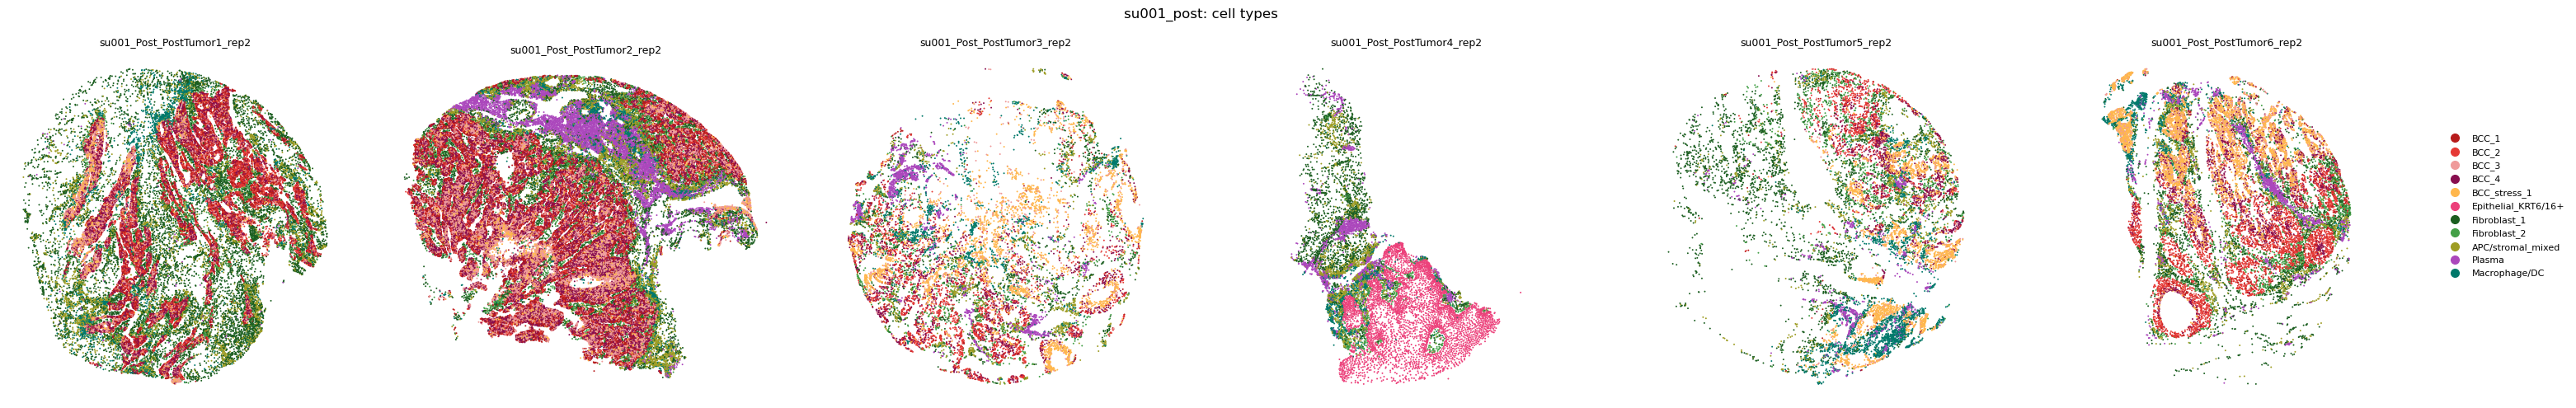

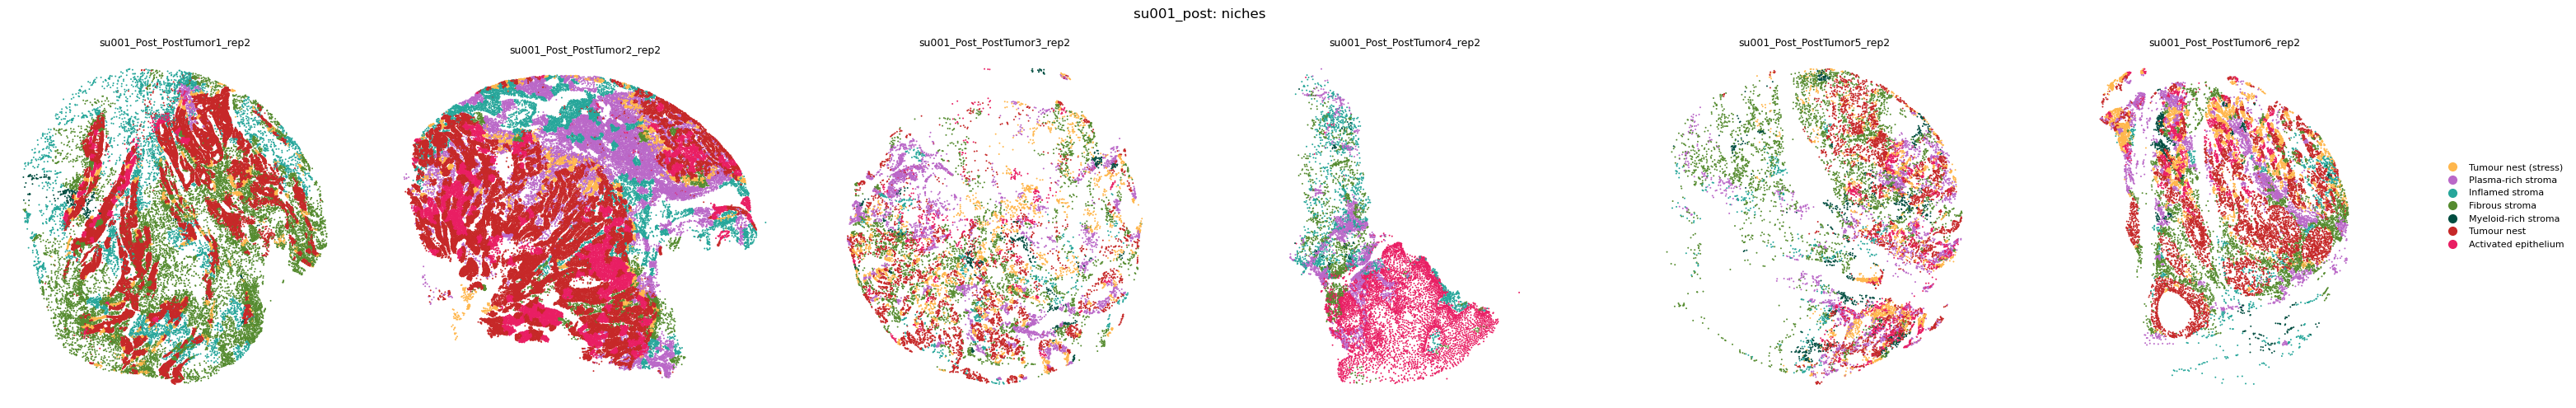

In [16]:
#Post
CHOSEN_K = 16

cell_map = {'0':'BCC_1', '1':'BCC_2', '2':'APC/stromal_mixed', '3':'Fibroblast_2', '4':'BCC_stress_1',
            '5':'BCC_3', '6':'BCC_4', '7':'Fibroblast_1', '8':'Macrophage/DC', '9':'Plasma'}
T, TS = 'Tumour nest', 'Tumour nest (stress)'
niche_maps = {16: {'0':TS, '1':'Myeloid-rich stroma', '2':T, '3':'Plasma-rich stroma', '4':TS, '5':TS,
                   '6':T, '7':'Inflamed stroma', '8':'Activated epithelium', '9':'Fibrous stroma',
                   '10':TS, '11':'Fibrous stroma', '12':T, '13':T, '14':'Plasma-rich stroma', '15':T}}

niche_key = f'niche_k{CHOSEN_K}'
adata.obs['cell_type']  = adata.obs[cell_key].astype(str).map(cell_map)
adata.obs['niche_type'] = adata.obs[niche_key].astype(str).map(niche_maps[CHOSEN_K])

# Post·Tumor4: no PTCH2+ cells (≤2% in every cluster), KRT16/S100A8 high -> activated epithelium, no BCC
is_t4 = adata.obs['sample_id'].astype(str).str.contains('PostTumor4').values
epi_cl = adata.obs[cell_key].astype(str).isin(['0', '1', '4', '5', '6']).values
adata.obs.loc[is_t4 & epi_cl, 'cell_type'] = 'Epithelial_KRT6/16+'
tum_niche = adata.obs['niche_type'].isin([T, TS]).values
adata.obs.loc[is_t4 & tum_niche, 'niche_type'] = 'Activated epithelium'
print('Tumor4 relabelled:', int((is_t4 & epi_cl).sum()), 'cells,', int((is_t4 & tum_niche).sum()), 'niche cells')

assert adata.obs[['cell_type', 'niche_type']].isna().sum().sum() == 0, 'unmapped clusters'

# CSV
orig_idx = adata.obs_names.str.rsplit('|', n=1).str[0]
cell_id  = adata.obs['sample_id'].astype(str).values + '|' + orig_idx
out = pd.DataFrame({'cell_type':  adata.obs['cell_type'].values,
                    'niche_type': adata.obs['niche_type'].values},
                   index=pd.Index(cell_id, name='cell_id'))
out.to_csv(OUT_DIR / f'{RUN_NAME}_cell_niche_annotation.csv')

# plots
plot_annotation(adata, 'cell_type',  CELL_PALETTE,  f'{RUN_NAME}: cell types', OUT_DIR / f'{RUN_NAME}_celltype.png')
plot_annotation(adata, 'niche_type', NICHE_PALETTE, f'{RUN_NAME}: niches',     OUT_DIR / f'{RUN_NAME}_niche.png')

# Excel sheet
ANNOT_XLSX = Path('./results_v2/su001_annotation.xlsx')
mode = 'a' if ANNOT_XLSX.exists() else 'w'
kw = {'if_sheet_exists': 'replace'} if mode == 'a' else {}
with pd.ExcelWriter(ANNOT_XLSX, mode=mode, engine='openpyxl', **kw) as w:
    out.to_excel(w, sheet_name='post')

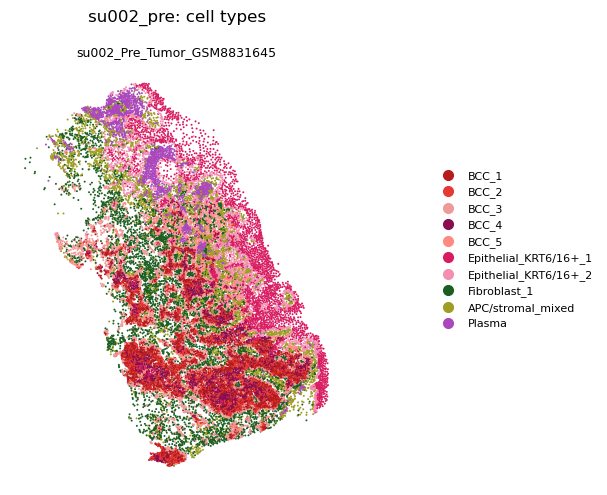

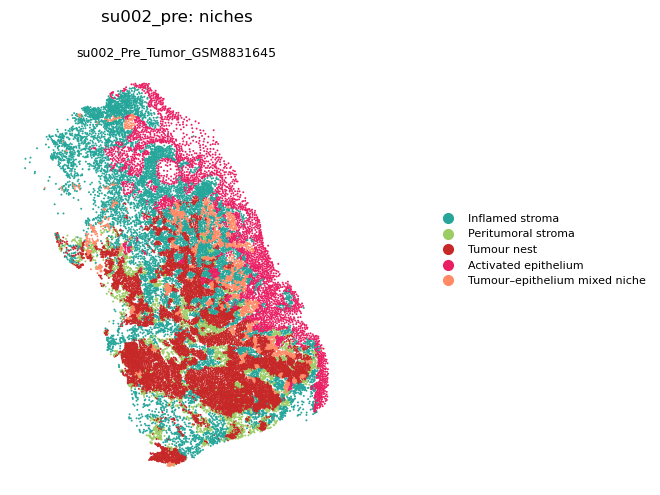

In [14]:
#su002 pre
CHOSEN_K = 8
NICHE_PALETTE.update({'Tumour–epithelium mixed niche':'#FF8A65'})

cell_map = {'0':'Plasma', '1':'BCC_4', '2':'Fibroblast_1', '3':'BCC_1', '4':'BCC_5', '5':'BCC_2',
            '6':'Epithelial_KRT6/16+_1', '7':'APC/stromal_mixed', '8':'BCC_3', '9':'Epithelial_KRT6/16+_2'}
M = 'Tumour–epithelium mixed niche'
niche_maps = {8: {'0':'Peritumoral stroma', '1':'Tumour nest', '2':M, '3':'Activated epithelium',
                  '4':'Inflamed stroma', '5':'Tumour nest', '6':'Activated epithelium', '7':M}}

# annotation
niche_key = f'niche_k{CHOSEN_K}'
adata.obs['cell_type']  = adata.obs[cell_key].astype(str).map(cell_map)
adata.obs['niche_type'] = adata.obs[niche_key].astype(str).map(niche_maps[CHOSEN_K])
assert adata.obs[['cell_type', 'niche_type']].isna().sum().sum() == 0, 'unmapped clusters'

# CSV (cell_id = sample|index)
orig_idx = adata.obs_names.str.rsplit('|', n=1).str[0]
cell_id  = adata.obs['sample_id'].astype(str).values + '|' + orig_idx
out = pd.DataFrame({'cell_type':  adata.obs['cell_type'].values,
                    'niche_type': adata.obs['niche_type'].values},
                   index=pd.Index(cell_id, name='cell_id'))
out.to_csv(OUT_DIR / f'{RUN_NAME}_cell_niche_annotation.csv')

# plots
plot_annotation(adata, 'cell_type',  CELL_PALETTE,  f'{RUN_NAME}: cell types', OUT_DIR / f'{RUN_NAME}_celltype.png')
plot_annotation(adata, 'niche_type', NICHE_PALETTE, f'{RUN_NAME}: niches',     OUT_DIR / f'{RUN_NAME}_niche.png')

# Excel: one file per patient, one sheet per run
patient, run = RUN_NAME.split('_', 1)                    # su002, pre
ANNOT_XLSX = Path(f'./results_v2/{patient}_annotation.xlsx')
mode = 'a' if ANNOT_XLSX.exists() else 'w'
kw = {'if_sheet_exists': 'replace'} if mode == 'a' else {}
with pd.ExcelWriter(ANNOT_XLSX, mode=mode, engine='openpyxl', **kw) as w:
    out.to_excel(w, sheet_name=run)

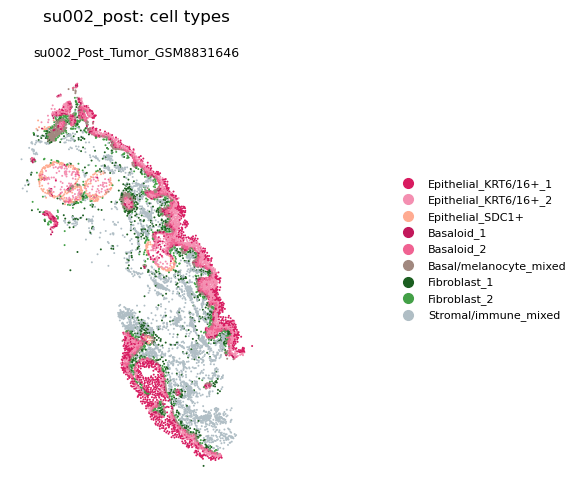

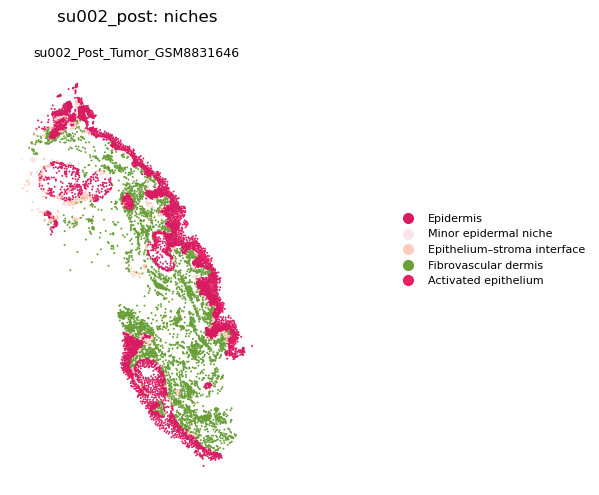

In [13]:
#su002 post
CHOSEN_K = 8
CELL_PALETTE.update({'Stromal/immune_mixed':'#B0BEC5'})

cell_map = {'0':'Basaloid_1', '1':'Stromal/immune_mixed', '2':'Epithelial_KRT6/16+_1', '3':'Epithelial_SDC1+',
            '4':'Basaloid_2', '5':'Fibroblast_1', '6':'Epithelial_KRT6/16+_2', '7':'Fibroblast_2',
            '8':'Basal/melanocyte_mixed', '9':'Basal/melanocyte_mixed'}
I, D = 'Epithelium–stroma interface', 'Fibrovascular dermis'
niche_maps = {8: {'0':'Activated epithelium', '1':'Epidermis', '2':D, '3':I,
                  '4':D, '5':'Minor epidermal niche', '6':I, '7':I}}

# annotation
niche_key = f'niche_k{CHOSEN_K}'
adata.obs['cell_type']  = adata.obs[cell_key].astype(str).map(cell_map)
adata.obs['niche_type'] = adata.obs[niche_key].astype(str).map(niche_maps[CHOSEN_K])
assert adata.obs[['cell_type', 'niche_type']].isna().sum().sum() == 0, 'unmapped clusters'

# CSV (cell_id = sample|index)
orig_idx = adata.obs_names.str.rsplit('|', n=1).str[0]
cell_id  = adata.obs['sample_id'].astype(str).values + '|' + orig_idx
out = pd.DataFrame({'cell_type':  adata.obs['cell_type'].values,
                    'niche_type': adata.obs['niche_type'].values},
                   index=pd.Index(cell_id, name='cell_id'))
out.to_csv(OUT_DIR / f'{RUN_NAME}_cell_niche_annotation.csv')

# plots
plot_annotation(adata, 'cell_type',  CELL_PALETTE,  f'{RUN_NAME}: cell types', OUT_DIR / f'{RUN_NAME}_celltype.png')
plot_annotation(adata, 'niche_type', NICHE_PALETTE, f'{RUN_NAME}: niches',     OUT_DIR / f'{RUN_NAME}_niche.png')

# Excel: one file per patient, one sheet per run
patient, run = RUN_NAME.split('_', 1)
ANNOT_XLSX = Path(f'./results_v2/{patient}_annotation.xlsx')
mode = 'a' if ANNOT_XLSX.exists() else 'w'
kw = {'if_sheet_exists': 'replace'} if mode == 'a' else {}
with pd.ExcelWriter(ANNOT_XLSX, mode=mode, engine='openpyxl', **kw) as w:
    out.to_excel(w, sheet_name=run)

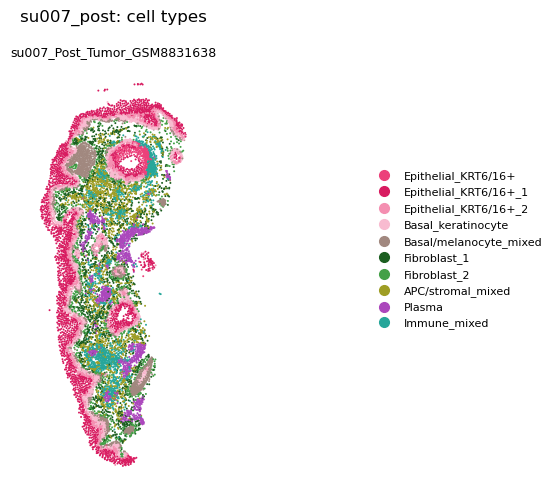

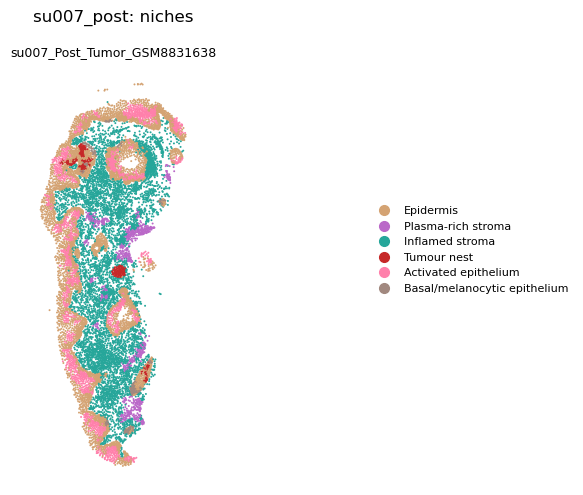

In [22]:
#su007 post
CHOSEN_K = 8
NICHE_PALETTE.update({'Activated epithelium': '#FF80AB', "Epidermis": "#D4A373",'Fibrovascular dermis': '#AED581'})

cell_map = {'0':'Fibroblast_1', '1':'Epithelial_KRT6/16+_1', '2':'Immune_mixed', '3':'Basal_keratinocyte',
            '4':'Fibroblast_2', '5':'Basal/melanocyte_mixed', '6':'Plasma', '7':'APC/stromal_mixed',
            '8':'Epithelial_KRT6/16+_2', '9':'Epithelial_KRT6/16+'}
A = 'Activated epithelium'
niche_maps = {8: {'0':'Inflamed stroma', '1':'Tumour nest', '2':A, '3':'Epidermis', '4':A,
                  '5':'Plasma-rich stroma', '6':A, '7':'Basal/melanocytic epithelium'}}

# annotation
niche_key = f'niche_k{CHOSEN_K}'
adata.obs['cell_type']  = adata.obs[cell_key].astype(str).map(cell_map)
adata.obs['niche_type'] = adata.obs[niche_key].astype(str).map(niche_maps[CHOSEN_K])
assert adata.obs[['cell_type', 'niche_type']].isna().sum().sum() == 0, 'unmapped clusters'

# CSV (cell_id = sample|index)
orig_idx = adata.obs_names.str.rsplit('|', n=1).str[0]
cell_id  = adata.obs['sample_id'].astype(str).values + '|' + orig_idx
assert pd.Index(cell_id).is_unique, 'cell_id is not unique'
out = pd.DataFrame({'cell_type':  adata.obs['cell_type'].values,
                    'niche_type': adata.obs['niche_type'].values},
                   index=pd.Index(cell_id, name='cell_id'))
out.to_csv(OUT_DIR / f'{RUN_NAME}_cell_niche_annotation.csv')

# plots
plot_annotation(adata, 'cell_type',  CELL_PALETTE,  f'{RUN_NAME}: cell types', OUT_DIR / f'{RUN_NAME}_celltype.png')
plot_annotation(adata, 'niche_type', NICHE_PALETTE, f'{RUN_NAME}: niches',     OUT_DIR / f'{RUN_NAME}_niche.png')

# Excel: one file per patient, one sheet per run
patient, run = RUN_NAME.split('_', 1)
ANNOT_XLSX = Path(f'./results_v2/{patient}_annotation.xlsx')
mode = 'a' if ANNOT_XLSX.exists() else 'w'
kw = {'if_sheet_exists': 'replace'} if mode == 'a' else {}
with pd.ExcelWriter(ANNOT_XLSX, mode=mode, engine='openpyxl', **kw) as w:
    out.to_excel(w, sheet_name=run)

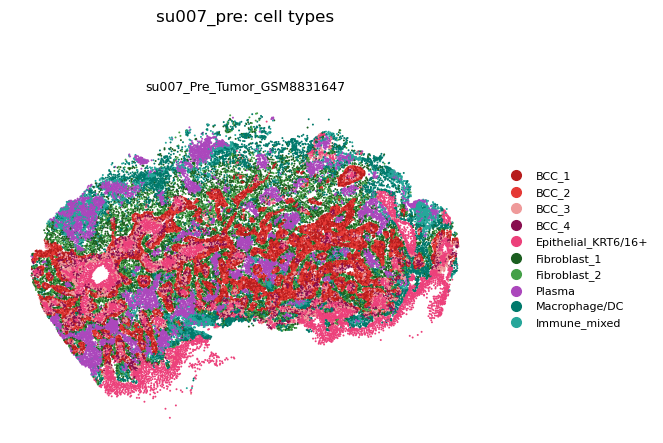

no colour for: ['Tumour–epithelium mixed niche'] → grey


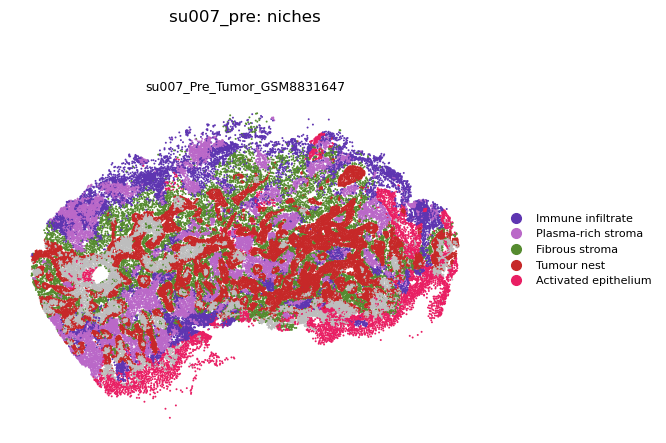

In [15]:
#su007 pre
CHOSEN_K = 10

cell_map = {'0':'Macrophage/DC', '1':'BCC_1', '2':'Epithelial_KRT6/16+', '3':'Plasma', '4':'Fibroblast_1',
            '5':'BCC_2', '6':'BCC_3', '7':'Fibroblast_2', '8':'Immune_mixed', '9':'BCC_4'}
T = 'Tumour nest'
niche_maps = {10: {'0':'Activated epithelium', '1':'Plasma-rich stroma', '2':'Immune infiltrate',
                   '3':'Tumour–epithelium mixed niche', '4':'Fibrous stroma',
                   '5':T, '6':T, '7':T, '8':T, '9':T}}

# annotation
niche_key = f'niche_k{CHOSEN_K}'
adata.obs['cell_type']  = adata.obs[cell_key].astype(str).map(cell_map)
adata.obs['niche_type'] = adata.obs[niche_key].astype(str).map(niche_maps[CHOSEN_K])
assert adata.obs[['cell_type', 'niche_type']].isna().sum().sum() == 0, 'unmapped clusters'

# CSV (cell_id = sample|index)
orig_idx = adata.obs_names.str.rsplit('|', n=1).str[0]
cell_id  = adata.obs['sample_id'].astype(str).values + '|' + orig_idx
out = pd.DataFrame({'cell_type':  adata.obs['cell_type'].values,
                    'niche_type': adata.obs['niche_type'].values},
                   index=pd.Index(cell_id, name='cell_id'))
out.to_csv(OUT_DIR / f'{RUN_NAME}_cell_niche_annotation.csv')

# plots
plot_annotation(adata, 'cell_type',  CELL_PALETTE,  f'{RUN_NAME}: cell types', OUT_DIR / f'{RUN_NAME}_celltype.png')
plot_annotation(adata, 'niche_type', NICHE_PALETTE, f'{RUN_NAME}: niches',     OUT_DIR / f'{RUN_NAME}_niche.png')

# Excel: one file per patient, one sheet per run
patient, run = RUN_NAME.split('_', 1)
ANNOT_XLSX = Path(f'./results_v2/{patient}_annotation.xlsx')
mode = 'a' if ANNOT_XLSX.exists() else 'w'
kw = {'if_sheet_exists': 'replace'} if mode == 'a' else {}
with pd.ExcelWriter(ANNOT_XLSX, mode=mode, engine='openpyxl', **kw) as w:
    out.to_excel(w, sheet_name=run)